# Deep velocity streamlines — MESACLIP piControl
One-year mean velocity at a fixed depth from the 0.1° POP run, regridded with xesmf onto a global lon/lat grid and drawn
as streamlines.

In [1]:
from pathlib import Path

import cartopy.crs as ccrs
import cmocean.cm as cmo
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import xesmf
from matplotlib.colors import LightSource, ListedColormap

## Settings

In [2]:
# Input
MONTHLY_DATA_DIR = Path.home() / "MESACLIP_piControl_500year_monthly"
DATA_FILE        = "B.E.13.B1850C5.ne120_t12.sehires38.003.sunway_02.pop.h.{var}.051001-051912.nc"   # years 510–519
POP_GRID_FILE    = "/glade/campaign/cesm/cesmdata/inputdata/ocn/pop/tx0.1v2/grid/horiz_grid_200709.ieeer8"
TOPO_PATH        = "/glade/campaign/cesm/cesmdata/inputdata/atm/cam/topo/USGS-gtopo30_10min_c050419.nc"

YEAR  = 519   # annual mean of this model year
DEPTH = 4000   # m; the nearest model level is used

# Map
MAP_RESOLUTION        = 1.0   # ° lon/lat grid the velocity is regridded onto
STREAMLINE_RESOLUTION = 0.5   # ° grid the streamlines are traced on
SPEED_RANGE           = (0, 5)   # cm/s
OCEAN_COLOR           = "#0b1a2e"

# Output
WEIGHTS_FILE = f"../data/pop_to_{MAP_RESOLUTION}deg_bilinear.nc"
FIGURE_FILE  = f"../plots/velocity_streamlines_{DEPTH}m_year{YEAR}.png"

## Velocity at DEPTH

In [3]:
def open_pop(var):
    return xr.open_dataset(MONTHLY_DATA_DIR / DATA_FILE.format(var=var), decode_timedelta=True)


velocity_file = open_pop("UVEL")
level = int(np.abs(velocity_file.z_t / 100 - DEPTH).argmin())
level_depth = float(velocity_file.z_t[level]) / 100   # m
# POP stamps each monthly mean at the start of the next month, so Jan–Dec of YEAR is stamped Feb 1 to Jan 1
year = slice(f"{YEAR:04d}-02-01", f"{YEAR + 1:04d}-01-01")
u = velocity_file.UVEL.isel(z_t=level).sel(time=year).mean("time")
v = open_pop("VVEL").VVEL.isel(z_t=level).sel(time=year).mean("time")

# POP velocities follow the grid lines; ANGLE rotates them to east/north
angle = velocity_file.ANGLE
flow = xr.Dataset(dict(east=u * np.cos(angle) - v * np.sin(angle),
                       north=u * np.sin(angle) + v * np.cos(angle))).load()
print(f"model level: {level_depth:.0f} m")

model level: 3876 m


## Regrid to lon/lat
The output files have lat/lon = -1 on POP's removed land blocks, which ESMF rejects, so the U-point coordinates
come from the model grid file. The weights are saved and reused.

In [4]:
u_lat, u_lon = np.rad2deg(np.fromfile(POP_GRID_FILE, ">f8", count=2 * angle.size).reshape(2, *angle.shape))
source = xr.Dataset(coords=dict(lat=(angle.dims, u_lat), lon=(angle.dims, u_lon)))
source["mask"] = velocity_file.HU > 0
target = xesmf.util.grid_global(MAP_RESOLUTION, MAP_RESOLUTION, cf=True, lon1=180)

saved = Path(WEIGHTS_FILE).exists()
regridder = xesmf.Regridder(source, target, "bilinear", periodic=True, unmapped_to_nan=True,
                            weights=WEIGHTS_FILE if saved else None)
if not saved:
    regridder.to_netcdf(WEIGHTS_FILE)

flow_map = regridder(flow)

lines_coarsen = max(1, round(STREAMLINE_RESOLUTION / MAP_RESOLUTION))
flow_lines = flow_map.coarsen(lat=lines_coarsen, lon=lines_coarsen, boundary="trim").mean().fillna(0)
speed = np.hypot(flow_lines.east, flow_lines.north)

## Map

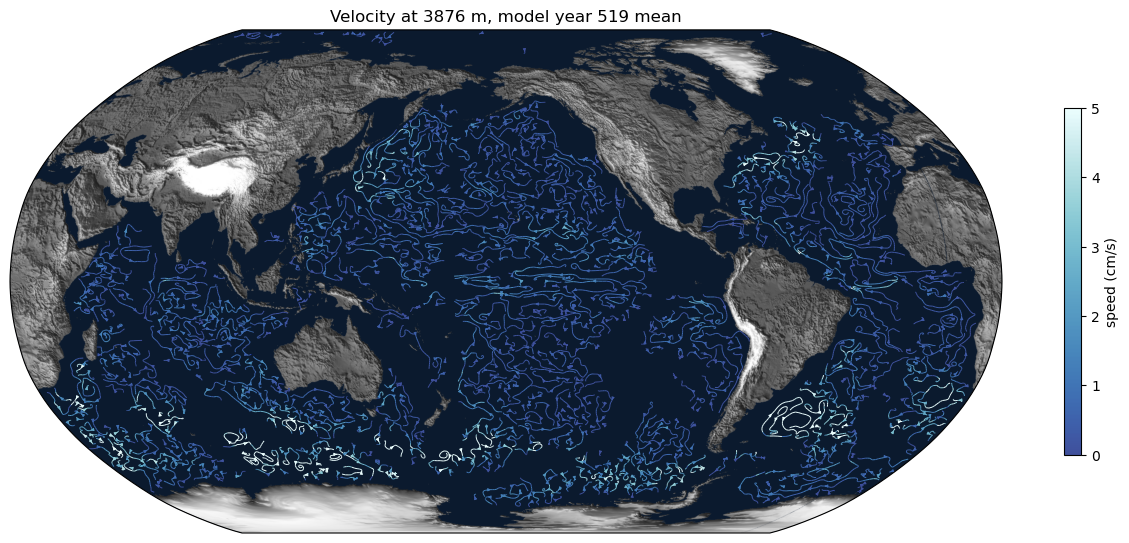

In [5]:
topo = xr.open_dataset(TOPO_PATH)
shade = LightSource(azdeg=315, altdeg=35)
land = shade.shade(topo.htopo.clip(min=0).values, cmap=plt.cm.gray, vmin=-1500, vmax=4500, blend_mode="soft", vert_exag=0.05)
land[..., 3] = topo.landfract.values > 0.5

plate = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(16, 9), subplot_kw=dict(projection=ccrs.Robinson(central_longitude=200)))
ax.set_global()
ax.set_facecolor(OCEAN_COLOR)
ax.imshow(land, origin="lower", extent=[float(topo.lon[0]), float(topo.lon[-1]), -90, 90], transform=plate, regrid_shape=2000)
streams = ax.streamplot(flow_lines.lon.values, flow_lines.lat.values, flow_lines.east.values, flow_lines.north.values,
                        transform=plate,
                        color=speed.values, cmap=ListedColormap(cmo.ice(np.linspace(0.35, 1, 256))), norm=plt.Normalize(*SPEED_RANGE),
                        density=8, linewidth=0.7, arrowsize=0.4)
fig.colorbar(streams.lines, ax=ax, shrink=0.5, label="speed (cm/s)")
ax.set_title(f"Velocity at {level_depth:.0f} m, model year {YEAR} mean")
fig.savefig(FIGURE_FILE, dpi=200, bbox_inches="tight")